# Results for the report
Tables and plots for Section 5 of *Constrained Decision Mamba & Constrained Decision ConvFormer*.

- **Normalized reward** = (R − r_min) / (r_max − r_min) × 100. Higher is better.
- **Normalized cost** = C / κ, where κ is the cost threshold. A value ≤ 1 means safe.
- Every model is evaluated on 3 cost thresholds × 3 seeds per environment (20 episodes each); results are mean ± sd over seeds.
- `BUDGET` in the setup cell picks the threshold(s) for Section 5.3: `"all"` averages the three thresholds, `10` uses only
  κ = 10 (the report's default threshold, and the setting of Nikola's experiment).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
RESULTS = ROOT / "experiments" / "results"
FIGURES = RESULTS / "main" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

CHECKPOINT = "last"   # "last" = final model (100k steps), "best" = checkpoint selected on validation
BUDGET = "all"        # Section 5.3: "all" = mean over the three cost thresholds, 10 = only kappa = 10

MODELS = {"cdt": "CDT", "cdt_light": "Lightweight CDT", "cdm": "CDMamba", "cdc": "CDConvFormer"}
COLORS = {"cdt": "#2a78d6", "cdt_light": "#86b6ef", "cdm": "#eb6834", "cdc": "#1baf7a"}
TASKS = {"AntRun": "Ant-Run", "CarCircle": "Car-Circle", "CarRun": "Car-Run",
         "DroneCircle": "Drone-Circle", "DroneRun": "Drone-Run"}
PAPER_CDT = {"AntRun": (89.76, 0.83), "CarCircle": (89.53, 0.85), "CarRun": (99.00, 0.45),   # (reward, cost) from
             "DroneCircle": (73.01, 0.88), "DroneRun": (63.64, 0.58)}                         # the CDT paper (Table 1)

plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e4e3df", "axes.axisbelow": True, "legend.frameon": False,
                     "savefig.dpi": 300, "savefig.bbox": "tight"})

held = pd.read_csv(RESULTS / "main" / "heldout_per_budget_per_seed.csv").query("checkpoint == @CHECKPOINT")
if BUDGET != "all":
    held = held.query("target_cost == @BUDGET")
budget = pd.read_csv(RESULTS / "main" / "budget_adaptation.csv").query("checkpoint == @CHECKPOINT")
times = pd.read_csv(RESULTS / "main" / "training_time.csv")
bench = pd.read_csv(RESULTS / "benchmark.csv")

## 5.3 Reward and safety performance
**Table 1.** Normalized reward and cost per environment, next to the numbers reported in the CDT paper. With
`BUDGET = "all"` a run's score is the mean over its three cost thresholds; with `BUDGET = 10` it is the κ = 10 result.
*Average* is the mean over the five environments.

In [2]:
runs = (held.groupby(["model", "task", "seed"])
        .agg(reward=("normalized_reward", "mean"), cost=("normalized_cost", "mean")).reset_index())
runs["reward"] *= 100
perf = runs.groupby(["model", "task"])[["reward", "cost"]].agg(["mean", "std"])

table1 = pd.DataFrame(index=list(TASKS.values()) + ["Average"])
paper = np.array([PAPER_CDT[t] for t in TASKS])
table1["CDT (paper) reward ↑"] = [f"{v:.1f}" for v in paper[:, 0]] + [f"{paper[:, 0].mean():.1f}"]
table1["CDT (paper) cost ↓"] = [f"{v:.2f}" for v in paper[:, 1]] + [f"{paper[:, 1].mean():.2f}"]
for m, name in MODELS.items():
    p = perf.loc[m].loc[list(TASKS)]
    table1[f"{name} reward ↑"] = [f"{a:.1f} ± {s:.1f}" for a, s in p["reward"].values] + [f"{p['reward', 'mean'].mean():.1f}"]
    table1[f"{name} cost ↓"] = [f"{a:.2f} ± {s:.2f}" for a, s in p["cost"].values] + [f"{p['cost', 'mean'].mean():.2f}"]
table1

,CDT (paper) reward ↑,CDT (paper) cost ↓,CDT reward ↑,CDT cost ↓,Lightweight CDT reward ↑,Lightweight CDT cost ↓,CDMamba reward ↑,CDMamba cost ↓,CDConvFormer reward ↑,CDConvFormer cost ↓
Ant-Run,89.8,0.83,68.5 ± 1.1,0.88 ± 0.05,67.1 ± 0.6,0.89 ± 0.02,69.4 ± 0.7,0.81 ± 0.04,68.0 ± 0.4,0.93 ± 0.03
Car-Circle,89.5,0.85,70.7 ± 1.3,0.79 ± 0.02,70.7 ± 0.5,0.76 ± 0.07,69.6 ± 1.6,0.82 ± 0.06,69.3 ± 1.9,0.78 ± 0.13
Car-Run,99.0,0.45,97.2 ± 0.5,0.74 ± 0.15,97.1 ± 0.5,0.78 ± 0.07,89.9 ± 1.4,0.88 ± 0.04,97.7 ± 0.3,0.98 ± 0.17
Drone-Circle,73.0,0.88,55.9 ± 1.5,1.02 ± 0.06,55.1 ± 1.4,1.02 ± 0.06,55.9 ± 0.6,1.01 ± 0.03,55.5 ± 2.7,1.11 ± 0.07
Drone-Run,63.6,0.58,56.6 ± 1.9,1.79 ± 0.15,48.5 ± 10.4,1.65 ± 0.17,51.0 ± 1.1,1.61 ± 0.47,41.3 ± 2.9,1.88 ± 0.39
Average,83.0,0.72,69.8,1.04,67.7,1.02,67.2,1.03,66.4,1.14


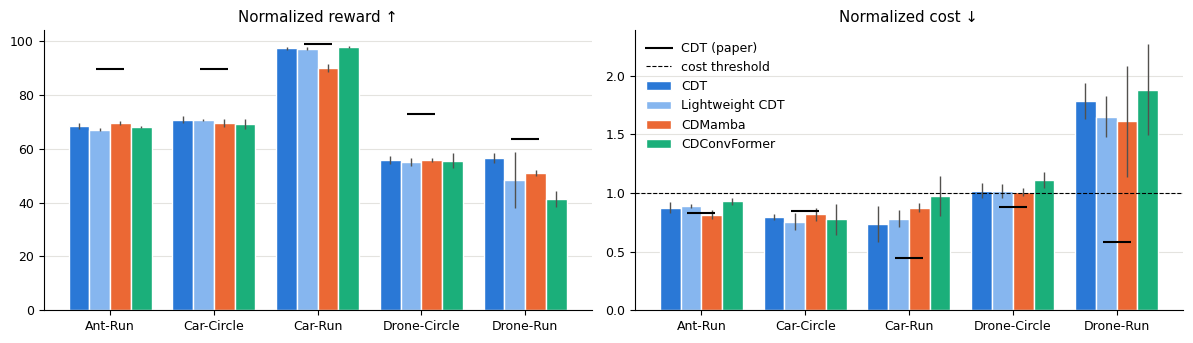

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
x, width = np.arange(len(TASKS)), 0.2
for i, (m, name) in enumerate(MODELS.items()):
    p = perf.loc[m].loc[list(TASKS)]
    for ax, metric in zip(axes, ["reward", "cost"]):
        ax.bar(x + (i - 1.5) * width, p[metric, "mean"], width, yerr=p[metric, "std"], color=COLORS[m],
               edgecolor="white", label=name, error_kw=dict(lw=1, ecolor="#52514e"))
for ax, col in zip(axes, [0, 1]):
    ax.scatter(x, paper[:, col], marker="_", s=400, color="black", zorder=4, label="CDT (paper)")
axes[1].axhline(1, color="black", lw=0.8, ls="--", label="cost threshold")
for ax, title in zip(axes, ["Normalized reward ↑", "Normalized cost ↓"]):
    ax.set_xticks(x, TASKS.values())
    ax.set_title(title)
    ax.grid(axis="x", visible=False)
axes[1].legend(loc="upper left")
fig.tight_layout()
fig.savefig(FIGURES / f"reward_cost_{CHECKPOINT}_budget-{BUDGET}.pdf")
plt.show()

## 5.4 Computational efficiency
**Table 2.** Parameters, inference latency (time for one action), peak GPU memory and training time. Latency and
memory were measured on CarRun on an A100 at the training context length (K = 10). Training time is the mean over all
runs, excluding evaluation.

In [4]:
b = bench.query("seq_len == 10").set_index("model")
table2 = pd.DataFrame({
    "Parameters (M)": b["parameters"] / 1e6,
    "Inference latency (ms)": b["action_latency_ms"],
    "Peak GPU memory, training (GB)": b["train_peak_mb"] / 1024,
    "Peak GPU memory, inference (MB)": b["inference_peak_mb"],
    "Training time (h)": times.groupby("model")["train_hours"].mean(),
}).loc[list(MODELS)].rename(index=MODELS)
table2.style.format("{:.2f}")

,Parameters (M),Inference latency (ms),"Peak GPU memory, training (GB)","Peak GPU memory, inference (MB)",Training time (h)
model,,,,,
CDT,0.63,2.23,0.20,28.30,4.77
Lightweight CDT,0.43,1.76,0.15,25.27,3.99
CDMamba,0.44,5.62,0.13,25.46,9.02
CDConvFormer,0.44,2.22,0.14,25.44,4.37


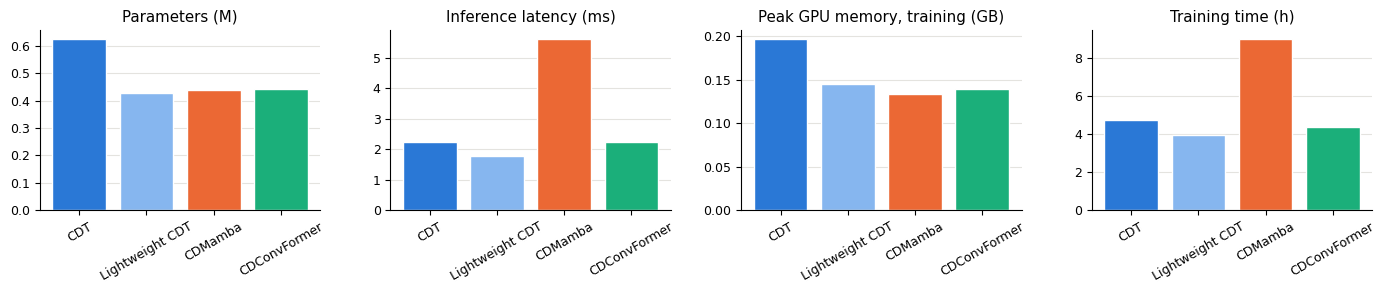

In [5]:
columns = ["Parameters (M)", "Inference latency (ms)", "Peak GPU memory, training (GB)", "Training time (h)"]
fig, axes = plt.subplots(1, 4, figsize=(14, 3))
for ax, column in zip(axes, columns):
    ax.bar(table2.index, table2[column], color=[COLORS[m] for m in MODELS], edgecolor="white")
    ax.set_title(column)
    ax.tick_params(axis="x", rotation=30)
    ax.grid(axis="x", visible=False)
fig.tight_layout()
fig.savefig(FIGURES / "efficiency.pdf")
plt.show()

**Scaling with context length.** Transformers become more expensive as the context length K grows (quadratically,
in theory); Mamba and ConvFormer should grow more slowly. Training uses K = 10; the benchmark also measured K = 20, 50 and 100.

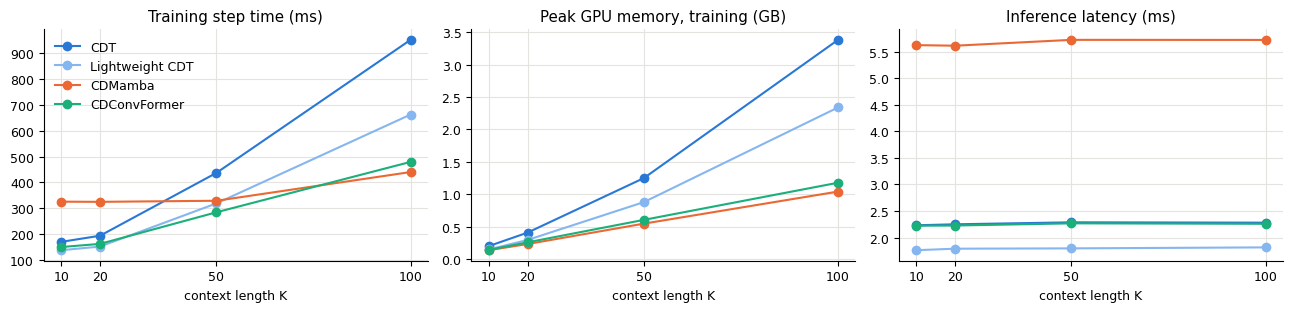

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
for m, name in MODELS.items():
    g = bench.query("model == @m").sort_values("seq_len")
    axes[0].plot(g["seq_len"], g["train_step_ms"], marker="o", color=COLORS[m], label=name)
    axes[1].plot(g["seq_len"], g["train_peak_mb"] / 1024, marker="o", color=COLORS[m])
    axes[2].plot(g["seq_len"], g["action_latency_ms"], marker="o", color=COLORS[m])
for ax, title in zip(axes, ["Training step time (ms)", "Peak GPU memory, training (GB)", "Inference latency (ms)"]):
    ax.set_title(title)
    ax.set_xlabel("context length K")
    ax.set_xticks([10, 20, 50, 100])
axes[0].legend()
fig.tight_layout()
fig.savefig(FIGURES / "context_scaling.pdf")
plt.show()

## 5.5 Zero-shot cost-budget adaptation
The same trained model is evaluated at three cost thresholds by changing only the target cost. **Top:** cost reached
vs the threshold that was asked for; points under the dashed line are within budget. **Bottom:** the normalized reward
at each threshold.

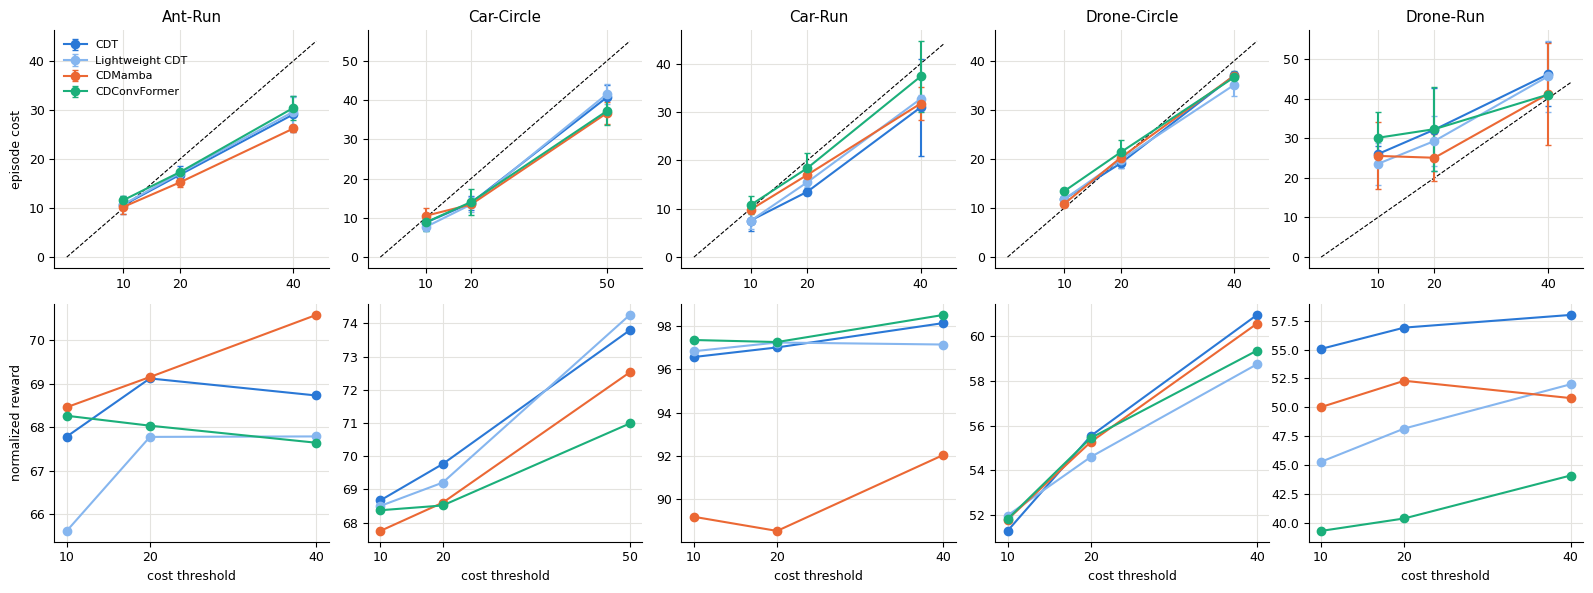

In [7]:
fig, axes = plt.subplots(2, len(TASKS), figsize=(16, 6))
for j, (task, title) in enumerate(TASKS.items()):
    targets = sorted(budget.query("task == @task")["target_cost"].unique())
    axes[0, j].plot([0, max(targets) * 1.1], [0, max(targets) * 1.1], color="black", lw=0.8, ls="--")
    for m, name in MODELS.items():
        g = budget.query("task == @task and model == @m").sort_values("target_cost")
        axes[0, j].errorbar(g["target_cost"], g["cost_mean"], yerr=g["cost_sd"], marker="o", color=COLORS[m],
                            capsize=2, label=name)
        axes[1, j].plot(g["target_cost"], g["normalized_reward_mean"], marker="o", color=COLORS[m])
    axes[0, j].set_title(title)
    axes[1, j].set_xlabel("cost threshold")
    for ax in axes[:, j]:
        ax.set_xticks(targets)
axes[0, 0].set_ylabel("episode cost")
axes[1, 0].set_ylabel("normalized reward")
axes[0, 0].legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES / f"budget_adaptation_{CHECKPOINT}.pdf")
plt.show()